# EDA Data Anomali SE2026 Kab. Banyumas

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_excel('../1908 Data_Mikro_Anomali_Gabungan_3302_20260819_092048.xlsx', dtype=str)
df.shape

C:\Users\Pongo\AppData\Local\Temp\ipykernel_9796\4012954790.py:4: Pandas4Warning: The default engine for reading 'xlsx' files will change from 'openpyxl' to 'calamine' in a future version. Pass engine='openpyxl' (or set the 'io.excel.xlsx.reader' option) to keep the current engine and silence this warning.
  df = pd.read_excel('../1908 Data_Mikro_Anomali_Gabungan_3302_20260819_092048.xlsx', dtype=str)


(19455, 63)

## 1. Pembersihan data
Buang baris nomor kolom, baris duplikat, dan kolom identitas.

In [2]:
df = df[df['No'] != '(1)'].drop_duplicates(subset=df.columns[:18])
df = df.drop(columns=['Nama Usaha / Kepala Keluarga', 'ID Petugas', 'Email Petugas', 'Link Fasih']).replace('-', pd.NA)
print(df.shape)
df[['Assignment ID', 'Daftar Anomali', 'Tindak Lanjut']].isna().sum()

(9727, 59)


Assignment ID     0
Daftar Anomali    0
Tindak Lanjut     0
dtype: int64

## 2. Pecah per anomali
1 baris = 1 jenis anomali pada 1 assignment.

In [3]:
df['jenis'] = df['Daftar Anomali'].str.findall(r'Anomali ([UK])\w+ (\d+)').apply(lambda x: [''.join(t) for t in x])
data = df.explode('jenis')
data['status'] = data['Tindak Lanjut'].str.extract('(Perbaikan|Penjelasan|Belum)', expand=False)
print('Anomali:', len(data), '| Assignment:', data['Assignment ID'].nunique())

Anomali: 15179 | Assignment: 7164


## 3. Distribusi frekuensi

status
Perbaikan     67.3
Penjelasan    23.9
Belum          8.8
Name: proportion, dtype: float64


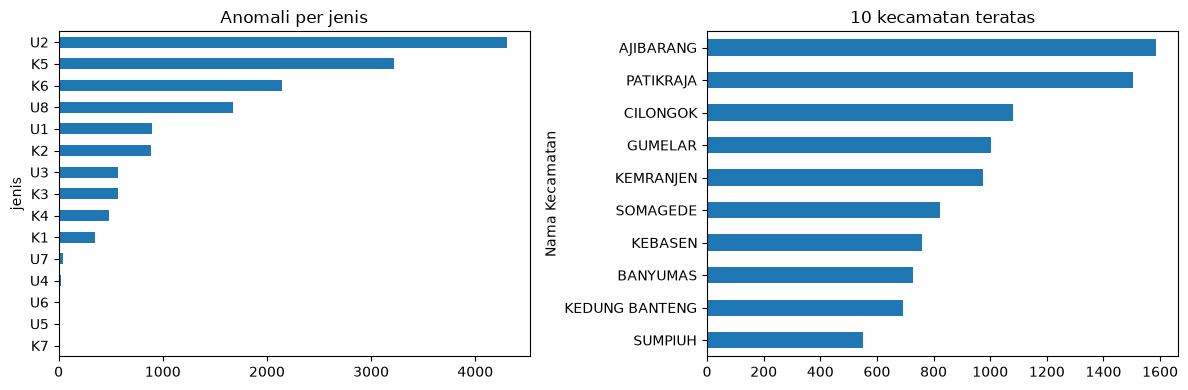

In [4]:
print(data['status'].value_counts(normalize=True).mul(100).round(1))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
data['jenis'].value_counts().sort_values().plot.barh(ax=ax[0], title='Anomali per jenis')
data['Nama Kecamatan'].value_counts().head(10).sort_values().plot.barh(ax=ax[1], title='10 kecamatan teratas')
plt.tight_layout()

## 4. Statistik deskriptif anomali per assignment

In [5]:
data.groupby('Assignment ID').size().describe().round(2)

count    7164.00
mean        2.12
std         1.12
min         1.00
25%         1.00
50%         2.00
75%         3.00
max         8.00
dtype: float64